# CarbonGlobe â€” `MM_LSTM_Age_XL`: a deeper, wider DeepED emulator

**IEEE Big Data Cup 2026 â€” CarbonGlobe AI Emulation Challenge**

Same data pipeline, rollout and submission as the baseline notebook, with a larger model built on the ideas
of `MM_LSTM_Age_v2` (â‰ˆ2Ã— the parameters, 3-layer BiLSTM encoder, state-aware input fusion, attention pooling).

* **Early stopping** on the real metric (full 40-year rollout on the held-out sites, every epoch);
  best weights are restored and saved to `/kaggle/working/<RUN_NAME>.weights.h5`.
* **LR scheduler**: linear warm-up â†’ ReduceLROnPlateau on the validation metric; gradient clipping.
* Faster pipeline: vectorized batch gathering (no per-sample Python generator), all 15 seed ages rolled out
  in one pass through a `tf.function`, states clipped at physical zero.
* Time budget guard so the run finishes inside a Kaggle session.
* The GitHub token is read from a Kaggle Secret (`GITHUB_TOKEN`) instead of being hard-coded.

## 0. Clone the repo & set up imports

In [1]:
import os, sys, subprocess, time, gc

REPO_DIR = '/kaggle/working/carbon-globe'
REPO_URL = 'github.com/kuongan/carbon-globe.git'

def _github_token():
    # Put the token in a Kaggle Secret named GITHUB_TOKEN (Add-ons -> Secrets).
    # Never hard-code it in the notebook: saved/committed notebooks leak it.
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret('GITHUB_TOKEN')
    except Exception:
        return os.environ.get('GITHUB_TOKEN', '')

if not os.path.isdir(REPO_DIR):
    tok = _github_token()
    url = f'https://{tok}@{REPO_URL}' if tok else f'https://{REPO_URL}'
    r = subprocess.run(['git', 'clone', '--depth', '1', url, REPO_DIR], capture_output=True, text=True)
    if r.returncode != 0:
        err = r.stderr.replace(tok, '***') if tok else r.stderr
        raise RuntimeError('git clone failed:\n' + err)

PKG_DIR = os.path.join(REPO_DIR, 'LSTM-LSTNet-DeepED')
sys.path.insert(0, PKG_DIR)
os.chdir(PKG_DIR)
print('cwd =', os.getcwd())
print('contents:', sorted(os.listdir(PKG_DIR)))

cwd = /kaggle/working/carbon-globe/LSTM-LSTNet-DeepED
contents: ['configs', 'models', 'run_LSTM.py', 'run_LSTNet.py', 'run_deeped.py', 'utils']


In [2]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tqdm.auto import tqdm

from configs.constant_glob import N_CONS, N_OUT, N_YEAR, N_T, N_FEA, TREE_BAND
from utils.func import normData, invNormData
from models.model import MM_LSTM_Age_v2   # repo baseline (also used as the param-count reference)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TF', tf.__version__, '| Keras', keras.__version__)
print('Repo constants: N_CONS=%d N_OUT=%d N_FEA=%d N_YEAR=%d N_T=%d' % (N_CONS, N_OUT, N_FEA, N_YEAR, N_T))
print('Targets:', TREE_BAND)

gpus = tf.config.list_physical_devices('GPU')
print('GPUs:', gpus)
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except Exception as e:
        print('memory growth note:', e)

TF 2.20.0 | Keras 3.13.2
Repo constants: N_CONS=136 N_OUT=7 N_FEA=158 N_YEAR=40 N_T=12
Targets: ['height', 'agb', 'soil', 'lai', 'gpp', 'npp', 'rh']
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1. Paths, constants & data stats

`y_mean[0]` / `y_mean[1]` are exactly the submission scale factors (height / 10.90645, agb / 3.39567).
`FLOOR_N` is physical zero expressed in standardized space; states are clipped there during rollout.

In [3]:
COMP = '/kaggle/input/competitions/ieee-bigdata-cup-2026-ai-emulation-challenge/public'
BASE = '/kaggle/input/datasets/zhihaow/carbonglobe'
OUT  = '/kaggle/working'

SEED_AGES = [1, 10, 20, 30, 50, 70, 100, 150, 200, 250, 300, 350, 400, 450, 500]
SCENARIOS = ['ssp126', 'ssp585']
N_AGES    = len(SEED_AGES)
N_AGE_FEA = 15

stats = np.load(f'{BASE}/data_stats/data_stats.npz')
X_MEAN, X_STD = stats['x_mean'].astype(np.float32), stats['x_std'].astype(np.float32)
Y_MEAN, Y_STD = stats['y_mean'].astype(np.float32), stats['y_std'].astype(np.float32)

agetri = np.load(f'{BASE}/data_stats/age_triplet.npz')
TRI_AGE   = agetri['age'].astype(np.float32)        # (15,)
TRI_MEAN  = agetri['age_mean'].astype(np.float32)   # (15,7)
TRI_SLOPE = agetri['age_slope'].astype(np.float32)  # (15,7)
assert list(TRI_AGE.astype(int)) == SEED_AGES

AGE_MEAN_N  = normData(TRI_MEAN,  Y_MEAN, Y_STD)
AGE_SLOPE_N = normData(TRI_SLOPE, Y_MEAN, Y_STD)
# 15-dim age feature per seed age: [age/500, age_mean_n(7), age_slope_n(7)]  (same layout the repo models slice)
AGE_FEAT = np.stack([np.concatenate([[TRI_AGE[i] / 500.0], AGE_MEAN_N[i], AGE_SLOPE_N[i]])
                     for i in range(N_AGES)]).astype(np.float32)          # (15,15)
FLOOR_N = normData(np.zeros(N_OUT, np.float32), Y_MEAN, Y_STD).astype(np.float32)  # physical 0, standardized

print('Y_MEAN =', np.round(Y_MEAN, 5))
print('FLOOR_N =', np.round(FLOOR_N, 4))
print('submission scale -> height /%.5f , agb /%.5f' % (Y_MEAN[0], Y_MEAN[1]))

Y_MEAN = [10.90644  3.39567  6.24214  1.88269  1.081    0.52339  0.489  ]
FLOOR_N = [-1.0517 -0.6479 -0.9987 -0.8665 -0.7287 -0.7223 -0.7823]
submission scale -> height /10.90645 , agb /3.39567


## 2. Load train / val arrays

Only the annual value (month 11) of `y` is kept. The forcing `x` is standardized **in place** once, so
the batch sampler and the per-epoch validation rollout never re-normalize it.

In [4]:
t0 = time.time()
res = np.load(f'{BASE}/data_global/res_train4_test8.npz', mmap_mode='r')

x_train = np.asarray(res['x_train'], dtype=np.float32)   # (N,40,12,136)
x_val   = np.asarray(res['x_test'],  dtype=np.float32)   # (Nval,40,12,136)
y_train = np.ascontiguousarray(res['y_train'][..., 11, :]).astype(np.float32)   # (15,N,41,7)
y_val   = np.ascontiguousarray(res['y_test'][...,  11, :]).astype(np.float32)   # (15,Nval,41,7)
res.close(); gc.collect()

def standardize_inplace(x):
    if not x.flags.writeable:
        x = x.copy()
    x -= X_MEAN
    x /= (X_STD + 1e-10)          # identical to utils.func.normData
    return x

x_train   = standardize_inplace(x_train)                           # standardized forcing
x_val     = standardize_inplace(x_val)
y_train_n = normData(y_train, Y_MEAN, Y_STD).astype(np.float32)    # standardized annual states
del y_train; gc.collect()

val_y0   = y_val[:, :, 0, :]      # (15,Nval,7) physical year-0
val_true = y_val[:, :, 40, :]     # (15,Nval,7) physical year-40

N_TRAIN = x_train.shape[0]
N_PAIRS = N_AGES * N_YEAR * N_TRAIN
print('loaded in %.1fs' % (time.time() - t0))
print('x_train', x_train.shape, 'y_train_n', y_train_n.shape, '| x_val', x_val.shape, 'y_val', y_val.shape)
print('one-step pairs per full pass:', N_PAIRS)

loaded in 28.1s
x_train (3373, 40, 12, 136) y_train_n (15, 3373, 41, 7) | x_val (852, 40, 12, 136) y_val (15, 852, 41, 7)
one-step pairs per full pass: 2023800


## 3. Model: `MM_LSTM_Age_XL` (deeper / wider DeepED)

Keeps what makes `MM_LSTM_Age_v2` work (per-target branches, gated LSTMs, age triplet, **residual on the
previous state**) and scales it up:

* input projection that fuses the monthly forcing with the current state + age context (v2's shared LSTM
  never sees the previous state);
* 3-layer **bidirectional** shared LSTM encoder with residual + LayerNorm (all 12 months of the year are
  observed inputs, so looking both ways is legitimate);
* 7 branches with 320-unit LSTMs; the gate uses a cuDNN LSTM + sigmoid Dense (v2's `activation='sigmoid'`
  LSTM falls back to the slow non-cuDNN kernel);
* attention pooling over months + last step, 512â†’128 MLP with dropout, and the head sees **all 7** previous
  states (cross-variable coupling);
* zero-initialised output head, so training starts from persistence (`next = prev`).

In [5]:
class GatedBranch(layers.Layer):
    """Per-target branch: gated LSTM stack -> attention pooling -> MLP -> residual delta."""
    def __init__(self, idx, units, mlp_units, dropout, **kw):
        super().__init__(name=f'branch{idx}', **kw)
        self.idx = idx
        self.lstm_data = layers.LSTM(units, return_sequences=True)
        self.lstm_gate = layers.LSTM(units, return_sequences=True)
        self.gate      = layers.Dense(units, activation='sigmoid')
        self.lstm_out  = layers.LSTM(units, return_sequences=True)
        self.norm      = layers.LayerNormalization(epsilon=1e-5)
        self.pool      = layers.Dense(1)
        self.mlp1      = layers.Dense(mlp_units, activation='gelu')
        self.mlp2      = layers.Dense(128, activation='gelu')
        self.drop      = layers.Dropout(dropout)
        self.head      = layers.Dense(1, kernel_initializer='zeros', bias_initializer='zeros')

    def call(self, h, prev, age, training=False):
        i = self.idx
        T = tf.shape(h)[1]
        age_i = tf.concat([age[:, :1], age[:, i + 1:i + 2], age[:, i + 8:i + 9]], axis=-1)   # (B,3)
        loc = tf.concat([prev[:, i:i + 1], age_i], axis=-1)                                 # (B,4)
        z = tf.concat([h, tf.repeat(loc[:, None, :], T, axis=1)], axis=-1)
        s = self.lstm_data(z) * self.gate(self.lstm_gate(z))
        s = self.norm(self.lstm_out(s))                                                     # (B,T,U)
        w = tf.nn.softmax(self.pool(s), axis=1)
        feat = tf.concat([tf.reduce_sum(w * s, axis=1), s[:, -1]], axis=-1)
        feat = self.mlp2(self.drop(self.mlp1(feat), training=training))
        feat = tf.concat([feat, prev, age_i], axis=-1)
        return prev[:, i:i + 1] + self.head(feat)                                           # residual


class MM_LSTM_Age_XL(keras.Model):
    def __init__(self, n_out=N_OUT, n_cons=N_CONS, n_age_fea=N_AGE_FEA, d_model=320, n_shared=3,
                 branch_units=320, mlp_units=512, dropout=0.1, **kw):
        super().__init__(**kw)
        self.n_out, self.n_cons, self.n_age_fea = n_out, n_cons, n_age_fea
        self.ctx_proj = layers.Dense(128, activation='gelu')
        self.in_proj  = layers.Dense(d_model)
        self.in_norm  = layers.LayerNormalization(epsilon=1e-5)
        self.enc_lstms = [layers.Bidirectional(layers.LSTM(d_model // 2, return_sequences=True))
                          for _ in range(n_shared)]
        self.enc_norms = [layers.LayerNormalization(epsilon=1e-5) for _ in range(n_shared)]
        self.enc_drop  = layers.Dropout(dropout)
        self.target_branches = [GatedBranch(i, branch_units, mlp_units, dropout) for i in range(n_out)]

    def call(self, inputs, training=False):
        nc, no, na = self.n_cons, self.n_out, self.n_age_fea
        env  = inputs[:, :, :nc]
        prev = inputs[:, -1, nc:nc + no]
        age  = inputs[:, -1, nc + no:nc + no + na]
        T = tf.shape(env)[1]
        ctx = self.ctx_proj(tf.concat([prev, age], axis=-1))
        h = tf.concat([env, tf.repeat(ctx[:, None, :], T, axis=1)], axis=-1)
        h = self.in_norm(self.in_proj(h))
        for lstm, norm in zip(self.enc_lstms, self.enc_norms):
            h = norm(h + self.enc_drop(lstm(h), training=training))
        return tf.concat([b(h, prev, age, training=training) for b in self.target_branches], axis=-1)

## 4. Config

In [6]:
RUN_NAME = 'lstm_xl'

# ---- optimisation ----
BATCH_SIZE   = 1024          # batch for K=1; longer windows use smaller batches (ROLL_TOKENS)
ROLL_TOKENS  = 2048         # cap on batch*K per step (memory for back-prop through the rollout)
MIN_BATCH    = 64
BASE_LR      = 5e-4
MIN_LR       = 1e-5
WARMUP_STEPS = 1000         # linear warm-up from 0.1*BASE_LR
CLIP_NORM    = 1.0
Y_W          = [2., 2., 1., 1., 1., 1., 1.]   # emphasise the scored variables (height, agb)
CLAMP_NONNEG = True         # clip states at physical 0 during rollout (training + inference)

# ---- epochs, LR plateau, early stopping ----
MAX_EPOCHS        = 20
SAMPLES_PER_EPOCH = None     # model-steps per epoch (windows = this // K); None = one full pass
LR_FACTOR, LR_PATIENCE = 0.5, 2   # ReduceLROnPlateau on the VAL 40-year metric
ES_PATIENCE       = 5               # early stopping patience (epochs) on the same metric
MIN_DELTA         = 1e-4
TIME_BUDGET_H     = 9.0           # stop training after this many hours (Kaggle session = 12 h)

# ---- rollout curriculum: (start_epoch, K years per window, teacher-forcing prob for steps k>0) ----
CURRICULUM = [(1, 1, 1.00)]    # one-step-ahead training (same objective as the baseline notebook)
# To add scheduled-sampling rollout training (see the v2-scheduled-sampling notebook), use e.g.:
# CURRICULUM = [(1, 1, 1.0), (3, 4, 0.75), (5, 8, 0.5), (7, 12, 0.25), (9, 16, 0.0)]

INIT_WEIGHTS = ''           # optional *.weights.h5 from a previous run (e.g. attached Kaggle dataset)

def make_model():
    return MM_LSTM_Age_XL(d_model=320, n_shared=3, branch_units=320, mlp_units=512, dropout=0.1)

def make_optimizer(lr):
    opt = tf.keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4)
    try:   # no weight decay on biases / norm parameters
        opt.exclude_from_weight_decay(var_names=['bias', 'gamma', 'beta', 'layer_normalization', 'embeddings'])
    except Exception as e:
        print('exclude_from_weight_decay note:', e)
    return opt

## 5. Build the model

In [7]:
def build(model):
    _ = model(tf.zeros((2, N_T, N_FEA), tf.float32), training=False)
    return model

MODEL = build(make_model())
n_params = MODEL.count_params()
_ref = build(MM_LSTM_Age_v2(n_out=N_OUT, n_cons=N_CONS))
ref_params = _ref.count_params()
del _ref; gc.collect()
print(f'{RUN_NAME}: {n_params/1e6:.2f}M params  '
      f'(MM_LSTM_Age_v2 reference: {ref_params/1e6:.2f}M -> x{n_params/ref_params:.2f})')

if INIT_WEIGHTS:
    MODEL.load_weights(INIT_WEIGHTS)
    print('warm-started from', INIT_WEIGHTS)

optimizer = make_optimizer(BASE_LR)
try:
    optimizer.build(MODEL.trainable_variables)   # create slots eagerly (outside tf.function)
except Exception as e:
    print('optimizer.build note:', e)

I0000 00:00:1790697330.046504      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790697330.049750      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


lstm_xl: 22.72M params  (MM_LSTM_Age_v2 reference: 12.08M -> x1.88)


## 6. Training engine: window sampler, rollout-aware train step, validation rollout, LR & early stopping

* **Window sampler** â€” a training example is a window `(seed-age, site, start-year t0)` of `K` consecutive
  years. Batches are gathered with vectorized numpy indexing (much faster than the old per-sample generator).
  `K = 1` is exactly the original one-step-ahead training.
* **Train step** â€” unrolls `K` years. For step `k > 0` the previous state is the ground truth with probability
  `tf_ratio`, otherwise the model's own (clipped) prediction, with gradients flowing through the rollout.
* **Validation** â€” the real competition metric: a full 40-year rollout on held-out sites, every epoch.
* **LR schedule** â€” linear warm-up, then ReduceLROnPlateau on the validation metric. Gradients are clipped.
* **Early stopping** â€” on the validation metric, restores the best weights (also saved to disk).

In [8]:
FLOOR_T = tf.constant(FLOOR_N)
Y_W_T   = tf.constant(Y_W, tf.float32)
if SAMPLES_PER_EPOCH is None:
    SAMPLES_PER_EPOCH = N_PAIRS          # one full pass over all one-step pairs

# ---------------------------------------------------------------- data
def batch_size_for(K):
    return int(min(BATCH_SIZE, max(MIN_BATCH, ROLL_TOKENS // K)))

def window_batches(K, n_windows, batch, rng):
    """Yield standardized (env (B,K,12,136), states (B,K+1,7), age_feat (B,15))."""
    T0 = N_YEAR - K + 1                                # valid start years
    total = N_AGES * N_TRAIN * T0
    n = min(n_windows, total)
    idx = rng.choice(total, size=n, replace=False)     # no repeats inside an epoch
    kx, ky = np.arange(K), np.arange(K + 1)
    for s in range(0, n - batch + 1, batch):           # drop remainder -> static shapes
        b = idx[s:s + batch]
        ai, rem = np.divmod(b, N_TRAIN * T0)
        site, t0 = np.divmod(rem, T0)
        env = x_train[site[:, None], t0[:, None] + kx]                   # (B,K,12,136)
        yy  = y_train_n[ai[:, None], site[:, None], t0[:, None] + ky]    # (B,K+1,7)
        yield env, yy, AGE_FEAT[ai]

def make_dataset(K, n_windows, batch, rng):
    sig = (tf.TensorSpec((batch, K, N_T, N_CONS), tf.float32),
           tf.TensorSpec((batch, K + 1, N_OUT), tf.float32),
           tf.TensorSpec((batch, N_AGE_FEA), tf.float32))
    return (tf.data.Dataset.from_generator(lambda: window_batches(K, n_windows, batch, rng),
                                           output_signature=sig)
            .prefetch(8))

# ---------------------------------------------------------------- train step
@tf.function
def train_step(env, yy, af, tf_ratio):
    K = env.shape[1]                                   # static -> one trace per K
    B = tf.shape(env)[0]
    af_m = tf.repeat(af[:, None, :], N_T, axis=1)      # (B,12,15)
    with tf.GradientTape() as tape:
        prev = yy[:, 0]
        loss = 0.0
        for k in range(K):
            prev_m = tf.repeat(prev[:, None, :], N_T, axis=1)
            xk = tf.concat([env[:, k], prev_m, af_m], axis=-1)       # (B,12,158)
            pred = MODEL(xk, training=True)
            if CLAMP_NONNEG:
                pred = tf.maximum(pred, FLOOR_T)
            loss += tf.reduce_mean(Y_W_T * tf.square(pred - yy[:, k + 1]))
            if k < K - 1:   # scheduled sampling: truth w.p. tf_ratio, else own prediction
                keep_true = tf.cast(tf.random.uniform((B, 1)) < tf_ratio, tf.float32)
                prev = keep_true * yy[:, k + 1] + (1.0 - keep_true) * pred
        loss = loss / K
    grads = tape.gradient(loss, MODEL.trainable_variables)
    grads, gnorm = tf.clip_by_global_norm(grads, CLIP_NORM)
    optimizer.apply_gradients(zip(grads, MODEL.trainable_variables))
    return loss, gnorm

# ---------------------------------------------------------------- rollout / metric
@tf.function(reduce_retracing=True)
def infer(x):
    return MODEL(x, training=False)

def rollout(x, y0_raw, x_is_norm=False, desc=None, bs=8192):
    """40-year autoregressive rollout for all seed ages at once.
    x: (N,40,12,136) forcing (raw, or standardized if x_is_norm); y0_raw: (15,N,7) physical year-0.
    Returns the year-40 state in physical units, shape (15,N,7)."""
    N, A = x.shape[0], y0_raw.shape[0]
    prev = normData(y0_raw, Y_MEAN, Y_STD).reshape(A * N, N_OUT).astype(np.float32)   # rows = (age, site)
    site_idx = np.tile(np.arange(N), A)
    af_rows = AGE_FEAT[np.repeat(np.arange(A), N)]
    years = tqdm(range(N_YEAR), desc=desc, leave=False) if desc else range(N_YEAR)
    for t in years:
        env_t = x[:, t] if x_is_norm else normData(x[:, t], X_MEAN, X_STD).astype(np.float32)
        nxt = np.empty_like(prev)
        for s in range(0, A * N, bs):
            e = min(s + bs, A * N)
            xb = np.concatenate([env_t[site_idx[s:e]],
                                 np.repeat(prev[s:e, None, :], N_T, axis=1),
                                 np.repeat(af_rows[s:e, None, :], N_T, axis=1)], axis=-1)
            p = infer(tf.constant(xb, tf.float32)).numpy()
            nxt[s:e] = np.maximum(p, FLOOR_N) if CLAMP_NONNEG else p
        prev = nxt
    out = invNormData(prev, Y_MEAN, Y_STD).reshape(A, N, N_OUT)
    return np.maximum(out, 0.0) if CLAMP_NONNEG else out

def scored_metric(pred, true):
    ph, th = pred[..., 0] / Y_MEAN[0], true[..., 0] / Y_MEAN[0]
    pa, ta = pred[..., 1] / Y_MEAN[1], true[..., 1] / Y_MEAN[1]
    mse_h = float(np.mean((ph - th) ** 2)); mse_a = float(np.mean((pa - ta) ** 2))
    return 0.5 * (mse_h + mse_a), mse_h, mse_a

# ---------------------------------------------------------------- LR schedule & early stopping
def set_lr(opt, value):
    opt.learning_rate = float(value)

class LRController:
    """Linear warm-up per step, then ReduceLROnPlateau per epoch on the validation metric."""
    def __init__(self, opt, base_lr, warmup_steps, factor, patience, min_lr, min_delta):
        self.opt, self.base_lr, self.warmup = opt, base_lr, warmup_steps
        self.factor, self.patience, self.min_lr, self.min_delta = factor, patience, min_lr, min_delta
        self.step, self.best, self.wait = 0, np.inf, 0
        self.lr = base_lr * (0.1 if warmup_steps > 0 else 1.0)
        set_lr(opt, self.lr)

    def on_step(self):
        if self.step < self.warmup:
            self.lr = self.base_lr * (0.1 + 0.9 * (self.step + 1) / self.warmup)
            set_lr(self.opt, self.lr)
        self.step += 1

    def on_epoch(self, metric, counting=True):
        if metric < self.best - self.min_delta:
            self.best, self.wait = metric, 0
        elif counting and self.step >= self.warmup:
            self.wait += 1
            if self.wait >= self.patience and self.lr > self.min_lr:
                self.lr = max(self.lr * self.factor, self.min_lr)
                set_lr(self.opt, self.lr)
                self.wait = 0
                print(f'    ReduceLROnPlateau -> lr = {self.lr:.2e}')

class EarlyStopper:
    def __init__(self, patience, min_delta, path):
        self.patience, self.min_delta, self.path = patience, min_delta, path
        self.best, self.wait, self.best_epoch, self.best_weights = np.inf, 0, 0, None

    def update(self, metric, model, epoch, counting=True):
        """Returns True when training should stop."""
        if metric < self.best:
            if metric < self.best - self.min_delta:
                self.wait = 0
            elif counting:
                self.wait += 1
            self.best, self.best_epoch = metric, epoch
            self.best_weights = model.get_weights()
            try:
                model.save_weights(self.path)
            except Exception as e:
                print('    save_weights note:', e)
        elif counting:
            self.wait += 1
        return self.wait >= self.patience

def stage_for_epoch(ep):
    si = 0
    for j, (start, _, _) in enumerate(CURRICULUM):
        if ep >= start:
            si = j
    _, K, tfr = CURRICULUM[si]
    return si, K, tfr

print('curriculum (start_epoch, K, teacher-forcing):', CURRICULUM)
print('batch per K:', {K: batch_size_for(K) for _, K, _ in CURRICULUM})

curriculum (start_epoch, K, teacher-forcing): [(1, 1, 1.0)]
batch per K: {1: 1024}


## 7. Train (early stopping + LR scheduling, tqdm progress)

In [9]:
rng = np.random.default_rng(SEED)
lr_ctl  = LRController(optimizer, BASE_LR, WARMUP_STEPS, LR_FACTOR, LR_PATIENCE, MIN_LR, MIN_DELTA)
stopper = EarlyStopper(ES_PATIENCE, MIN_DELTA, f'{OUT}/{RUN_NAME}.weights.h5')

history, last_stage, t_start = [], None, time.time()
for ep in range(1, MAX_EPOCHS + 1):
    t_ep = time.time()
    si, K, tfr = stage_for_epoch(ep)
    counting = (si == len(CURRICULUM) - 1)          # patience only counts in the final stage
    if si != last_stage:
        if last_stage is not None:
            stopper.wait = 0; lr_ctl.wait = 0
        print(f'== stage {si}: K={K} years per window, teacher-forcing={tfr:.2f}')
        last_stage = si

    B = batch_size_for(K)
    n_win = max(B, SAMPLES_PER_EPOCH // K)
    steps = n_win // B
    tfr_t = tf.constant(tfr, tf.float32)
    running, nb = 0.0, 0
    pbar = tqdm(make_dataset(K, n_win, B, rng), total=steps, desc=f'epoch {ep}/{MAX_EPOCHS} K={K}')
    for env, yy, af in pbar:
        lr_ctl.on_step()
        loss, gnorm = train_step(env, yy, af, tfr_t)
        running += float(loss); nb += 1
        if nb % 50 == 0 or nb == steps:
            pbar.set_postfix(loss=f'{running/nb:.5f}', lr=f'{lr_ctl.lr:.1e}')
    train_loss = running / max(nb, 1)

    vpred = rollout(x_val, val_y0, x_is_norm=True)
    vscore, vh, va = scored_metric(vpred, val_true)
    stop = stopper.update(vscore, MODEL, ep, counting)
    lr_ctl.on_epoch(vscore, counting)

    ep_min = (time.time() - t_ep) / 60
    elapsed_h = (time.time() - t_start) / 3600
    history.append(dict(epoch=ep, K=K, tf_ratio=tfr, lr=lr_ctl.lr, train_loss=train_loss,
                        val_metric=vscore, val_mse_h=vh, val_mse_agb=va, minutes=ep_min))
    flag = ' *best*' if stopper.best_epoch == ep else ''
    print(f'  epoch {ep}: train {train_loss:.5f} | VAL-40y {vscore:.5f} (h {vh:.4f}, agb {va:.4f}) '
          f'| lr {lr_ctl.lr:.1e} | {ep_min:.1f} min{flag}')

    if stop:
        print(f'Early stopping at epoch {ep} (best epoch {stopper.best_epoch}, VAL {stopper.best:.5f})')
        break
    if elapsed_h + ep_min / 60 > TIME_BUDGET_H:
        print(f'Time budget reached ({elapsed_h:.2f} h) -> stop')
        break

if stopper.best_weights is not None:
    MODEL.set_weights(stopper.best_weights)
    print(f'restored best weights from epoch {stopper.best_epoch} (VAL {stopper.best:.5f})')
else:
    print('WARNING: validation metric never became finite; keeping the last weights')
hist_df = pd.DataFrame(history)
hist_df.to_csv(f'{OUT}/{RUN_NAME}_history.csv', index=False)
hist_df

== stage 0: K=1 years per window, teacher-forcing=1.00


epoch 1/20 K=1:   0%|          | 0/1976 [00:00<?, ?it/s]

  epoch 1: train 0.01220 | VAL-40y 0.08197 (h 0.0607, agb 0.1032) | lr 5.0e-04 | 24.9 min *best*


epoch 2/20 K=1:   0%|          | 0/1976 [00:00<?, ?it/s]

  epoch 2: train 0.00565 | VAL-40y 0.05172 (h 0.0497, agb 0.0537) | lr 5.0e-04 | 24.8 min *best*


epoch 3/20 K=1:   0%|          | 0/1976 [00:00<?, ?it/s]

... (14 outputs left out)

    ReduceLROnPlateau -> lr = 6.25e-05
  epoch 10: train 0.00125 | VAL-40y 0.04221 (h 0.0454, agb 0.0390) | lr 6.3e-05 | 24.7 min


epoch 11/20 K=1:   0%|          | 0/1976 [00:00<?, ?it/s]

  epoch 11: train 0.00110 | VAL-40y 0.03803 (h 0.0414, agb 0.0346) | lr 6.3e-05 | 25.0 min
Early stopping at epoch 11 (best epoch 6, VAL 0.03793)
restored best weights from epoch 6 (VAL 0.03793)


,epoch,K,tf_ratio,lr,train_loss,val_metric,val_mse_h,val_mse_agb,minutes
0,1,1,1.0,0.000500,0.012196,0.081974,0.060699,0.103249,24.908527
1,2,1,1.0,0.000500,0.005647,0.051715,0.049705,0.053725,24.752477
2,3,1,1.0,0.000500,0.004264,0.058111,0.058275,0.057947,25.099076
3,4,1,1.0,0.000250,0.003375,0.052937,0.056402,0.049471,25.104522
4,5,1,1.0,0.000250,0.002145,0.041563,0.048819,0.034308,25.104177
5,6,1,1.0,0.000250,0.001971,0.037929,0.039242,0.036616,24.999734
6,7,1,1.0,0.000250,0.001773,0.047193,0.051432,0.042954,24.687579
7,8,1,1.0,0.000125,0.001654,0.045094,0.053418,0.036770,24.683553
8,9,1,1.0,0.000125,0.001322,0.042719,0.050908,0.034531,24.699086
9,10,1,1.0,0.000063,0.001248,0.042211,0.045433,0.038988,24.707137


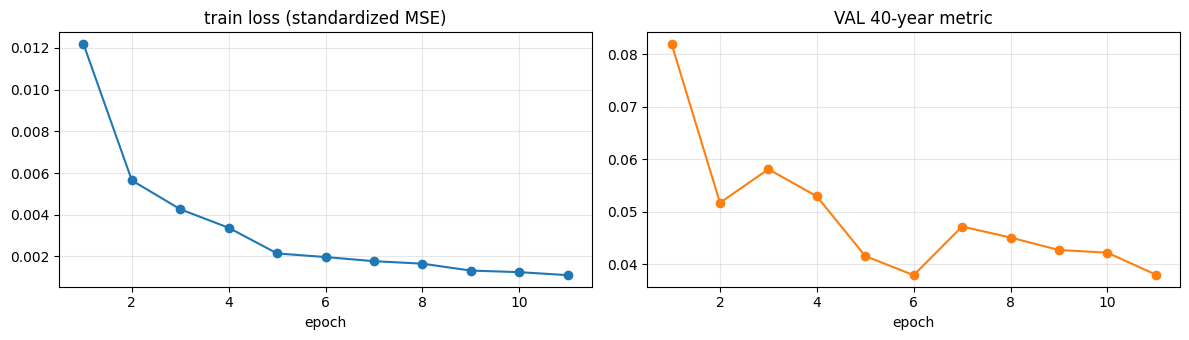

In [10]:
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(hist_df.epoch, hist_df.train_loss, marker='o'); ax[0].set_title('train loss (standardized MSE)')
    ax[1].plot(hist_df.epoch, hist_df.val_metric, marker='o', color='C1'); ax[1].set_title('VAL 40-year metric')
    for a in ax: a.set_xlabel('epoch'); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()
except Exception as e:
    print('plot skipped:', e)

## 8. Validation with the best weights

In [11]:
val_pred = rollout(x_val, val_y0, x_is_norm=True, desc='val rollout')
score, mse_h, mse_a = scored_metric(val_pred, val_true)
print(f'VAL scored metric = {score:.5f}  (height MSE {mse_h:.5f}, agb MSE {mse_a:.5f})')
print(f'VAL relative RMSE = {np.sqrt(score):.5f}')
print('note: the val set is also used for early stopping / LR decisions, so this is slightly optimistic.')

val rollout:   0%|          | 0/40 [00:00<?, ?it/s]

VAL scored metric = 0.03793  (height MSE 0.03924, agb MSE 0.03662)
VAL relative RMSE = 0.19475
note: the val set is also used for early stopping / LR decisions, so this is slightly optimistic.


## 9. Predict on the challenge test set & write the submission

In [12]:
def load_test(scn):
    d = np.load(f'{COMP}/test_{scn}.npz')
    return d['test_x'].astype(np.float32), d['test_y0'].astype(np.float32)

sample_sub = pd.read_csv(f'{COMP}/sample_submission.csv')
print('sample_submission rows:', len(sample_sub))

parts, raw_preds = [], {}
for scn in SCENARIOS:
    tx, ty0 = load_test(scn)                          # (N,40,12,136), (N,15,7)
    N = tx.shape[0]
    p = rollout(tx, np.transpose(ty0, (1, 0, 2)), desc=f'{scn} rollout')   # (15,N,7) physical
    raw_preds[scn] = p
    ids = [f'{scn}_{site}_{age}' for age in SEED_AGES for site in range(N)]
    parts.append(pd.DataFrame({'id': ids,
                               'height': (p[:, :, 0] / Y_MEAN[0]).reshape(-1),
                               'agb':    (p[:, :, 1] / Y_MEAN[1]).reshape(-1)}))
    del tx, ty0; gc.collect()

pred_df = pd.concat(parts).set_index('id')
sub = sample_sub[['id']].join(pred_df, on='id')

assert len(sub) == len(sample_sub), len(sub)
if len(sub) != 185130:
    print('WARNING: expected 185130 rows, got', len(sub))
assert list(sub.columns) == ['id', 'height', 'agb']
assert not sub[['height', 'agb']].isna().any().any(), 'NaNs / missing ids in submission!'

sub.to_csv(f'{OUT}/submission.csv', index=False)
# keep raw year-40 predictions so several runs can be ensembled later
np.savez_compressed(f'{OUT}/{RUN_NAME}_preds.npz', val_pred=val_pred, **raw_preds)
print('wrote', f'{OUT}/submission.csv', 'and', f'{OUT}/{RUN_NAME}_preds.npz')
print(sub.head())
print('\nheight scaled: mean %.3f std %.3f' % (sub['height'].mean(), sub['height'].std()))
print('agb    scaled: mean %.3f std %.3f' % (sub['agb'].mean(), sub['agb'].std()))

sample_submission rows: 185130


ssp126 rollout:   0%|          | 0/40 [00:00<?, ?it/s]

ssp585 rollout:   0%|          | 0/40 [00:00<?, ?it/s]

wrote /kaggle/working/submission.csv and /kaggle/working/lstm_xl_preds.npz
            id    height       agb
0   ssp126_0_1  0.052029  0.000000
1  ssp126_0_10  0.063763  0.000856
2  ssp126_0_20  0.066891  0.007136
3  ssp126_0_30  0.062006  0.012209
4  ssp126_0_50  0.052346  0.019665

height scaled: mean 1.020 std 0.979
agb    scaled: mean 0.917 std 1.386


## 10. Ensembling runs

Each run writes `<RUN_NAME>_preds.npz` (year-40 physical predictions for val + both test scenarios).
Averaging the files from the three notebooks (v2 scheduled-sampling, LSTM-XL, EcoFormer) is a cheap way to
cut rollout variance; weight them by their VAL metric if one is clearly better.